In [1]:
# Final Exam AIBD | Variant B: Bike Sharing (hour.csv) | Aktan Seraliyev, 255522, DBAIT-2501
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             silhouette_score, calinski_harabasz_score, davies_bouldin_score,
                             adjusted_rand_score)

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
sns.set_theme(style='whitegrid')

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
DATA = Path('data/hour.csv')
FIG = Path('figures'); FIG.mkdir(exist_ok=True)

def reg_metrics(name, part, y, p):
    return {'model': name, 'partition': part, 'n': len(y),
            'MAE': mean_absolute_error(y, p),
            'RMSE': np.sqrt(mean_squared_error(y, p)),
            'R2': r2_score(y, p)}

In [2]:
# Part 1. Load data and audit
if not DATA.exists():                       # Colab: upload hour.csv if it is not in data/
    from google.colab import files
    up = files.upload(); DATA.parent.mkdir(exist_ok=True); Path(next(iter(up))).rename(DATA)

raw = pd.read_csv(DATA)
raw['dteday'] = pd.to_datetime(raw['dteday'])
print('Shape:', raw.shape)
print('Period:', raw['dteday'].min().date(), 'to', raw['dteday'].max().date(), '|', raw['dteday'].nunique(), 'days')
print(raw.dtypes.value_counts())

hours_per_day = raw.groupby('dteday').size()
audit = pd.Series({
    'Missing cells': raw.isna().sum().sum(),
    'Duplicate rows': raw.duplicated().sum(),
    'Duplicate date-hour': raw.duplicated(['dteday', 'hr']).sum(),
    'Absent hours (731*24 - rows)': 731 * 24 - len(raw),
    'Days with < 24 rows': (hours_per_day < 24).sum(),
    'cnt == casual + registered': (raw['cnt'] == raw['casual'] + raw['registered']).all(),
    'weathersit == 4': (raw['weathersit'] == 4).sum(),
    'hum == 0': (raw['hum'] == 0).sum(),
    'windspeed == 0': (raw['windspeed'] == 0).sum(),
    'atemp < temp - 0.2': ((raw['temp'] - raw['atemp']) > 0.2).sum(),
})
display(audit.to_frame('value'))
display(hours_per_day[hours_per_day < 20].sort_values().to_frame('hours recorded'))
print('hum == 0 on:', raw.loc[raw['hum'] == 0, 'dteday'].dt.date.unique())
print('broken atemp on:', raw.loc[(raw['temp'] - raw['atemp']) > 0.2, 'dteday'].dt.date.unique())

Shape: (17379, 17)
Period: 2011-01-01 to 2012-12-31 | 731 days
int64             12
float64            4
datetime64[us]     1
Name: count, dtype: int64


,value
Missing cells,0
Duplicate rows,0
Duplicate date-hour,0
Absent hours (731*24 - rows),165
Days with < 24 rows,76
cnt == casual + registered,True
weathersit == 4,3
hum == 0,22
windspeed == 0,2180
atemp < temp - 0.2,24


,hours recorded
dteday,
2012-10-29,1
2011-01-27,8
2012-10-30,11
2011-01-18,12
2011-01-26,16
2011-08-28,17
2011-02-22,18
2011-08-27,18


hum == 0 on: [datetime.date(2011, 3, 10)]
broken atemp on: [datetime.date(2012, 8, 17)]


In [3]:
# Part 1. Data dictionary
dictionary = pd.DataFrame([
    ['instant', 'Row index', 'dropped'],
    ['dteday', 'Date', 'time index'],
    ['season', '1 winter, 2 spring, 3 summer, 4 autumn', 'feature'],
    ['yr', '0 = 2011, 1 = 2012', 'feature'],
    ['mnth', 'Month 1-12', 'feature'],
    ['hr', 'Hour 0-23', 'feature'],
    ['holiday', 'Public holiday 0/1', 'feature'],
    ['weekday', '0 = Sunday ... 6 = Saturday', 'feature'],
    ['workingday', 'Not weekend and not holiday 0/1', 'feature'],
    ['weathersit', '1 clear, 2 mist, 3 light rain/snow, 4 heavy rain/snow', 'feature (4 -> 3)'],
    ['temp', 'Temperature C / 41', 'feature'],
    ['atemp', 'Feels-like temperature C / 50', 'dropped (r = 0.99 with temp)'],
    ['hum', 'Humidity / 100', 'feature (0 -> missing)'],
    ['windspeed', 'Wind speed / 67', 'feature'],
    ['casual', 'Rentals by casual users', 'excluded (part of cnt)'],
    ['registered', 'Rentals by registered users', 'excluded (part of cnt)'],
    ['cnt', 'Total rentals in the hour', 'target'],
    ['lag24, lag168', 'cnt same hour 1 day / 7 days before', 'feature (created)'],
    ['hr_daytype', 'hr + 24 * workingday', 'feature (created)'],
], columns=['variable', 'meaning', 'use'])
display(dictionary)

,variable,meaning,use
0,instant,Row index,dropped
1,dteday,Date,time index
2,season,"1 winter, 2 spring, 3 summer, 4 autumn",feature
3,yr,"0 = 2011, 1 = 2012",feature
4,mnth,Month 1-12,feature
5,hr,Hour 0-23,feature
6,holiday,Public holiday 0/1,feature
7,weekday,0 = Sunday ... 6 = Saturday,feature
8,workingday,Not weekend and not holiday 0/1,feature
9,weathersit,"1 clear, 2 mist, 3 light rain/snow, 4 heavy ra...",feature (4 -> 3)


In [4]:
# Part 1. Cleaning decisions
df = raw.copy()
log = []
log.append(['weathersit 4 -> 3', (df['weathersit'] == 4).sum(), 'only 3 rows'])
df.loc[df['weathersit'] == 4, 'weathersit'] = 3
log.append(['hum 0 -> missing', (df['hum'] == 0).sum(), 'sensor fault on 2011-03-10'])
df.loc[df['hum'] == 0, 'hum'] = np.nan
log.append(['atemp dropped', len(df), 'duplicate of temp, broken on 2012-08-17'])
log.append(['casual, registered, instant not used', len(df), 'leakage / identifier'])

# lags on a full hourly grid, so that lag24 really means 24 hours before
df['ts'] = df['dteday'] + pd.to_timedelta(df['hr'], unit='h')
grid = pd.DataFrame({'ts': pd.date_range(df['ts'].min(), df['ts'].max(), freq='h')})
grid = grid.merge(df[['ts', 'cnt']], on='ts', how='left')
grid['lag24'] = grid['cnt'].shift(24)
grid['lag168'] = grid['cnt'].shift(168)
df = df.merge(grid[['ts', 'lag24', 'lag168']], on='ts', how='left')
log.append(['lag24 missing', df['lag24'].isna().sum(), 'first day or absent hour'])
log.append(['lag168 missing', df['lag168'].isna().sum(), 'first week or absent hour'])

df['hr_daytype'] = df['hr'] + 24 * df['workingday']
df = df.drop(columns=['instant', 'atemp'])
display(pd.DataFrame(log, columns=['decision', 'rows', 'reason']))

df.to_csv('data/hour_clean.csv', index=False)
print('Clean table:', df.shape)

,decision,rows,reason
0,weathersit 4 -> 3,3,only 3 rows
1,hum 0 -> missing,22,sensor fault on 2011-03-10
2,atemp dropped,17379,"duplicate of temp, broken on 2012-08-17"
3,"casual, registered, instant not used",17379,leakage / identifier
4,lag24 missing,160,first day or absent hour
5,lag168 missing,304,first week or absent hour


Clean table: (17379, 19)


In [5]:
# Part 2. Descriptive statistics
num = ['cnt', 'temp', 'hum', 'windspeed']
desc = df[num].describe().T
desc['skew'] = df[num].skew()
desc['IQR'] = desc['75%'] - desc['25%']
desc['outliers'] = [((df[c] > desc.loc[c, '75%'] + 1.5 * desc.loc[c, 'IQR'])).sum() for c in num]
display(desc)
for c in ['season', 'weathersit', 'workingday', 'holiday']:
    display(df.groupby(c)['cnt'].agg(['count', 'mean', 'median']))

,count,mean,std,min,25%,50%,75%,max,skew,IQR,outliers
cnt,"17,379.000",189.463,181.388,1.000,40.000,142.000,281.000,977.000,1.277,241.000,505
temp,"17,379.000",0.497,0.193,0.020,0.340,0.500,0.660,1.000,-0.006,0.320,0
hum,"17,357.000",0.628,0.192,0.080,0.480,0.630,0.780,1.000,-0.082,0.300,0
windspeed,"17,379.000",0.190,0.122,0.000,0.104,0.194,0.254,0.851,0.575,0.149,342


,count,mean,median
season,,,
1,4242,111.115,76.000
2,4409,208.344,165.000
3,4496,236.016,199.000
4,4232,198.869,155.500


,count,mean,median
weathersit,,,
1,11413,204.869,159.000
2,4544,175.165,133.000
3,1422,111.501,63.000


,count,mean,median
workingday,,,
0,5514,181.405,119.000
1,11865,193.208,151.000


,count,mean,median
holiday,,,
0,16879,190.429,144.000
1,500,156.870,97.000


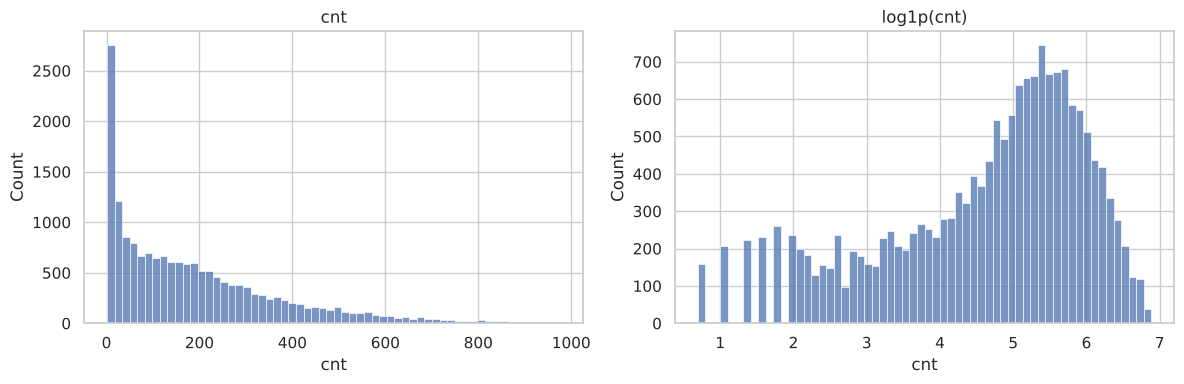

median 142.0 | mean 189.5 | hours with cnt <= 10: 1980


In [6]:
# Part 2. Figure 1 - distribution of hourly rentals
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['cnt'], bins=60, ax=ax[0]); ax[0].set_title('cnt')
sns.histplot(np.log1p(df['cnt']), bins=60, ax=ax[1]); ax[1].set_title('log1p(cnt)')
plt.tight_layout(); plt.savefig(FIG / 'f1_distribution.png', dpi=150); plt.show()
print('median', df['cnt'].median(), '| mean', round(df['cnt'].mean(), 1), '| hours with cnt <= 10:', (df['cnt'] <= 10).sum())

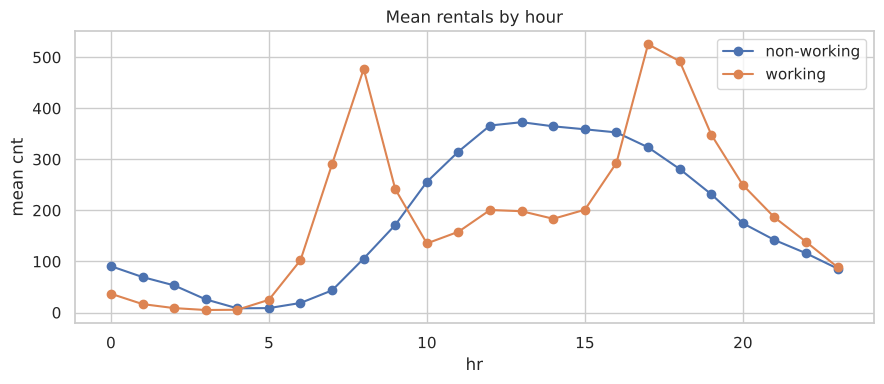

,non-working,working
hr,,
8,106.000,477.000
13,373.000,198.000
17,324.000,525.000


In [7]:
# Part 2. Figure 2 - hourly profile, working vs non-working days
prof = df.groupby(['hr', 'workingday'])['cnt'].mean().unstack()
prof.columns = ['non-working', 'working']
prof.plot(marker='o', figsize=(9, 4), title='Mean rentals by hour')
plt.ylabel('mean cnt'); plt.tight_layout(); plt.savefig(FIG / 'f2_hour_profile.png', dpi=150); plt.show()
display(prof.loc[[8, 13, 17]].round(0))

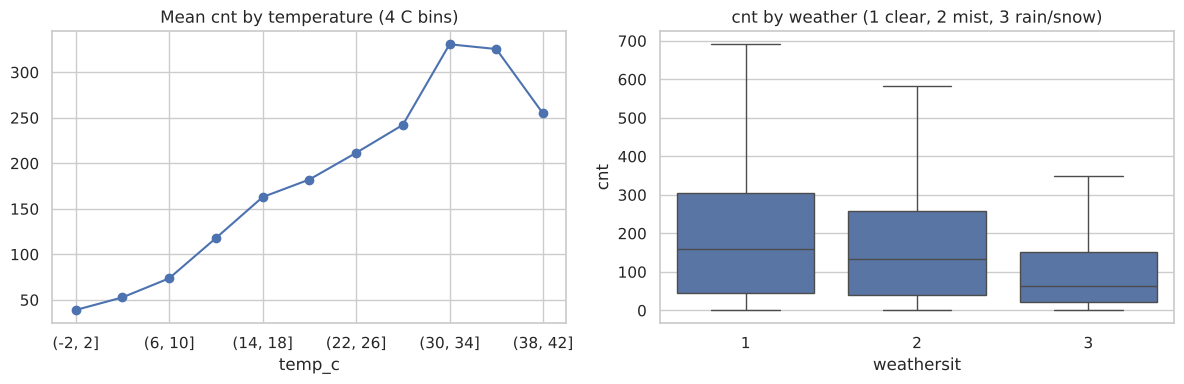

temp_c
(-2, 2]     39.000
(2, 6]      53.000
(6, 10]     74.000
(10, 14]   118.000
(14, 18]   163.000
(18, 22]   182.000
(22, 26]   211.000
(26, 30]   242.000
(30, 34]   331.000
(34, 38]   326.000
(38, 42]   255.000
Name: cnt, dtype: float64

In [8]:
# Part 2. Figure 3 - temperature and weather
df['temp_c'] = df['temp'] * 41
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
t_bins = df.groupby(pd.cut(df['temp_c'], range(-10, 45, 4)), observed=True)['cnt'].mean()
t_bins.plot(marker='o', ax=ax[0], title='Mean cnt by temperature (4 C bins)')
sns.boxplot(data=df, x='weathersit', y='cnt', showfliers=False, ax=ax[1])
ax[1].set_title('cnt by weather (1 clear, 2 mist, 3 rain/snow)')
plt.tight_layout(); plt.savefig(FIG / 'f3_weather.png', dpi=150); plt.show()
display(t_bins.round(0))
df = df.drop(columns='temp_c')

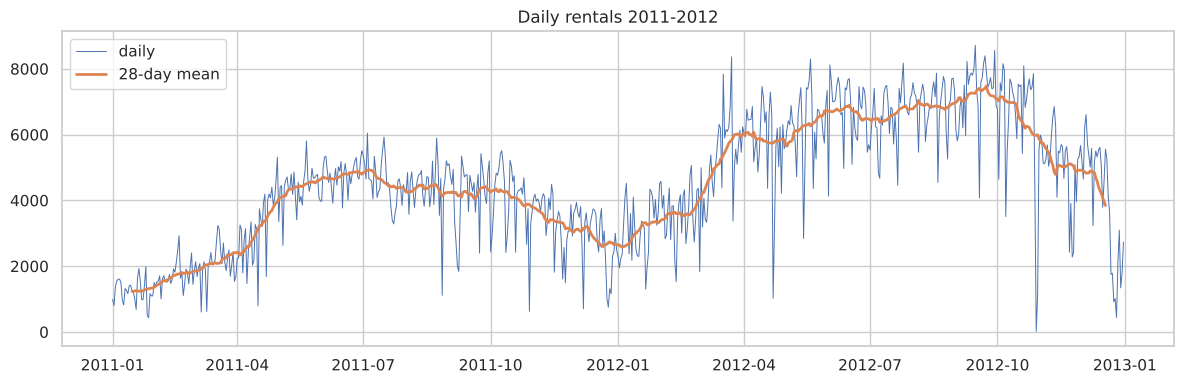

yr
0   3,406.000
1   5,600.000
Name: cnt, dtype: float64


,cnt,hours,rain_hours
dteday,,,
2012-10-29,22,1,1
2011-01-27,431,8,0
2012-12-26,441,24,16
2011-01-26,506,16,14
2011-03-06,605,23,9


In [9]:
# Part 2. Figure 4 - daily rentals over time
daily = df.groupby('dteday').agg(cnt=('cnt', 'sum'), temp=('temp', 'mean'), hum=('hum', 'mean'),
                                 windspeed=('windspeed', 'mean'), workingday=('workingday', 'first'),
                                 holiday=('holiday', 'first'), weekday=('weekday', 'first'),
                                 mnth=('mnth', 'first'), yr=('yr', 'first'),
                                 rain_hours=('weathersit', lambda s: (s == 3).sum()),
                                 hours=('cnt', 'size'))
plt.figure(figsize=(12, 4))
plt.plot(daily['cnt'], lw=0.7, label='daily')
plt.plot(daily['cnt'].rolling(28, center=True).mean(), lw=2, label='28-day mean')
plt.legend(); plt.title('Daily rentals 2011-2012')
plt.tight_layout(); plt.savefig(FIG / 'f4_daily.png', dpi=150); plt.show()
print(daily.groupby('yr')['cnt'].mean().round(0))
display(daily.nsmallest(5, 'cnt')[['cnt', 'hours', 'rain_hours']])

In [10]:
# Part 2. Statistical tests (day level)
print('Shapiro-Wilk on daily cnt, p =', stats.shapiro(daily['cnt']).pvalue)

# Test 1: share of rentals in commute hours, working vs non-working days (Mann-Whitney U)
commute = df[df['hr'].isin([7, 8, 9, 16, 17, 18, 19])].groupby('dteday')['cnt'].sum()
daily['commute_share'] = commute / daily['cnt']
full = daily[daily['hours'] >= 20]
a = full.loc[full['workingday'] == 1, 'commute_share']
b = full.loc[full['workingday'] == 0, 'commute_share']
u, p = stats.mannwhitneyu(a, b)
r = 2 * u / (len(a) * len(b)) - 1          # rank-biserial effect size
print(f'Test 1: median {a.median():.3f} vs {b.median():.3f}, n = {len(a)} vs {len(b)}, U = {u:.0f}, p = {p:.2e}, r = {r:.2f}')

a2 = daily.loc[daily['workingday'] == 1, 'cnt']
b2 = daily.loc[daily['workingday'] == 0, 'cnt']
u2, p2 = stats.mannwhitneyu(a2, b2)
print(f'Daily totals: median {a2.median():.0f} vs {b2.median():.0f}, p = {p2:.3f}, r = {2 * u2 / (len(a2) * len(b2)) - 1:.2f}')

# Test 2: daily temperature vs daily rentals (Spearman)
rho, p_rho = stats.spearmanr(daily['temp'], daily['cnt'])
print(f'Test 2: Spearman rho = {rho:.3f}, p = {p_rho:.2e}, n = {len(daily)}')
for y in (0, 1):
    print('   year', 2011 + y, 'rho =', round(stats.spearmanr(daily.loc[daily['yr'] == y, 'temp'], daily.loc[daily['yr'] == y, 'cnt'])[0], 3))

Shapiro-Wilk on daily cnt, p = 2.0812933057909132e-08
Test 1: median 0.586 vs 0.345, n = 494 vs 229, U = 112453, p = 1.55e-101, r = 0.99
Daily totals: median 4582 vs 4459, p = 0.119, r = 0.07
Test 2: Spearman rho = 0.622, p = 1.68e-79, n = 731
   year 2011 rho = 0.762
   year 2012 rho = 0.7


In [11]:
# Part 3. Chronological split
train = df[df['dteday'] < '2012-07-01'].copy()
val = df[(df['dteday'] >= '2012-07-01') & (df['dteday'] < '2012-10-01')].copy()
test = df[df['dteday'] >= '2012-10-01'].copy()
dev = pd.concat([train, val])
for name, part in [('train', train), ('validation', val), ('test', test)]:
    print(f"{name:11s} {len(part):6d} rows  {part['dteday'].min().date()} to {part['dteday'].max().date()}  mean cnt {part['cnt'].mean():.1f}")

for part in (train, val, test, dev):
    part['log_lag24'] = np.log1p(part['lag24'])
    part['log_lag168'] = np.log1p(part['lag168'])

CAT = ['hr_daytype', 'hr', 'weekday', 'mnth', 'season', 'weathersit']
NUM = ['temp', 'hum', 'windspeed', 'log_lag24', 'log_lag168']
BIN = ['yr', 'holiday', 'workingday']
FEATURES = CAT + NUM + BIN

# preprocessing for the linear model and MLP: fitted on training data only (inside the pipeline)
def make_prep():
    return ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='ignore'), CAT),
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), NUM),
        ('bin', 'passthrough', BIN)])

train        13003 rows  2011-01-01 to 2012-06-30  mean cnt 167.7
validation    2208 rows  2012-07-01 to 2012-09-30  mean cnt 288.4
test          2168 rows  2012-10-01 to 2012-12-31  mean cnt 219.2


In [12]:
# Part 3. PCA on the weather variables (fitted on train)
W = ['temp', 'atemp', 'hum', 'windspeed']
w_train = raw.loc[train.index, W].replace({'hum': {0: np.nan}})
pca_pipe = Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler()), ('pca', PCA())])
pca_pipe.fit(w_train)
pca = pca_pipe.named_steps['pca']
ev = pd.DataFrame({'explained': pca.explained_variance_ratio_,
                   'cumulative': pca.explained_variance_ratio_.cumsum()}, index=['PC1', 'PC2', 'PC3', 'PC4'])
display(ev)
display(pd.DataFrame(pca.components_.T, index=W, columns=ev.index).round(3))
print('corr(temp, atemp) =', round(w_train['temp'].corr(w_train['atemp']), 3))

# does PCA help the linear model? (validation)
prep_pca = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), CAT),
    ('w', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler()), ('pca', PCA(n_components=2))]), ['temp', 'hum', 'windspeed']),
    ('lag', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), ['log_lag24', 'log_lag168']),
    ('bin', 'passthrough', BIN)])
m_raw = Pipeline([('prep', make_prep()), ('m', Ridge(alpha=10))]).fit(train[FEATURES], np.log1p(train['cnt']))
m_pca = Pipeline([('prep', prep_pca), ('m', Ridge(alpha=10))]).fit(train[FEATURES], np.log1p(train['cnt']))
display(pd.DataFrame([reg_metrics('Ridge, weather variables', 'validation', val['cnt'], np.expm1(m_raw.predict(val[FEATURES]))),
                      reg_metrics('Ridge, 2 weather PCs', 'validation', val['cnt'], np.expm1(m_pca.predict(val[FEATURES])))]))

,explained,cumulative
PC1,0.499,0.499
PC2,0.324,0.823
PC3,0.175,0.998
PC4,0.002,1.000


,PC1,PC2,PC3,PC4
temp,0.706,0.001,0.053,-0.706
atemp,0.706,-0.031,0.028,0.707
hum,-0.055,-0.705,0.707,-0.004
windspeed,-0.026,0.709,0.704,0.028


corr(temp, atemp) = 0.992


,model,partition,n,MAE,RMSE,R2
0,"Ridge, weather variables",validation,2208,58.904,96.451,0.826
1,"Ridge, 2 weather PCs",validation,2208,58.280,95.076,0.831


In [13]:
# Part 4. Baseline and model tuning on the validation period
y_tr, y_val, y_test, y_dev = train['cnt'], val['cnt'], test['cnt'], dev['cnt']

def baseline(part):                               # same hour last week, then same hour yesterday
    return part['lag168'].fillna(part['lag24']).fillna(y_tr.median())

rows = [reg_metrics('Baseline: same hour last week', 'validation', y_val, baseline(val))]

for a in [1, 10, 30, 100, 300]:                   # Ridge on log(cnt)
    m = Pipeline([('prep', make_prep()), ('m', Ridge(alpha=a))]).fit(train[FEATURES], np.log1p(y_tr))
    rows.append(reg_metrics(f'Ridge alpha={a}', 'validation', y_val, np.expm1(m.predict(val[FEATURES]))))

X_tr_rf = train[FEATURES].fillna(train[FEATURES].median())   # random forest: no scaling needed
X_val_rf = val[FEATURES].fillna(train[FEATURES].median())
for leaf in [1, 5, 20]:
    rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=leaf, n_jobs=-1, random_state=RANDOM_STATE)
    rf.fit(X_tr_rf, y_tr)
    rows.append(reg_metrics(f'Random forest leaf={leaf}', 'validation', y_val, rf.predict(X_val_rf)))
tune = pd.DataFrame(rows)
display(tune)

,model,partition,n,MAE,RMSE,R2
0,Baseline: same hour last week,validation,2208,55.998,97.892,0.820
1,Ridge alpha=1,validation,2208,61.231,101.331,0.808
2,Ridge alpha=10,validation,2208,58.904,96.451,0.826
3,Ridge alpha=30,validation,2208,56.842,91.231,0.844
4,Ridge alpha=100,validation,2208,56.786,88.834,0.852
5,Ridge alpha=300,validation,2208,58.324,90.959,0.845
6,Random forest leaf=1,validation,2208,47.131,77.887,0.886
7,Random forest leaf=5,validation,2208,47.259,78.511,0.885
8,Random forest leaf=20,validation,2208,50.063,82.024,0.874


In [14]:
# Part 4. Final models (refit on train + validation), evaluated once on the test period
best_alpha = int(tune[tune['model'].str.startswith('Ridge')].sort_values('RMSE').iloc[0]['model'].split('=')[1])
best_leaf = int(tune[tune['model'].str.startswith('Random')].sort_values('RMSE').iloc[0]['model'].split('=')[1])
print('Chosen on validation: Ridge alpha =', best_alpha, '| Random forest min_samples_leaf =', best_leaf)

ridge = Pipeline([('prep', make_prep()), ('m', Ridge(alpha=best_alpha))]).fit(dev[FEATURES], np.log1p(y_dev))
p_ridge = np.expm1(ridge.predict(test[FEATURES]))

fill = dev[FEATURES].median()
rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=best_leaf, n_jobs=-1, random_state=RANDOM_STATE)
rf.fit(dev[FEATURES].fillna(fill), y_dev)
p_rf = rf.predict(test[FEATURES].fillna(fill))
p_base = baseline(test)

final = pd.DataFrame([reg_metrics('Baseline: same hour last week', 'test Oct-Dec 2012', y_test, p_base),
                      reg_metrics('Ridge (log cnt)', 'test Oct-Dec 2012', y_test, p_ridge),
                      reg_metrics('Random forest', 'test Oct-Dec 2012', y_test, p_rf)])
display(final)
# final model = lower RMSE on VALIDATION (not on test)
val_ridge = tune[tune['model'].str.startswith('Ridge')]['RMSE'].min()
val_rf = tune[tune['model'].str.startswith('Random')]['RMSE'].min()
best = final.iloc[2] if val_rf < val_ridge else final.iloc[1]
print(f'Validation RMSE: Ridge {val_ridge:.1f}, Random forest {val_rf:.1f} -> final model: {best["model"]}')
print(f"{best['model']} vs baseline: MAE {final.iloc[0]['MAE']:.1f} -> {best['MAE']:.1f} "
      f"({1 - best['MAE'] / final.iloc[0]['MAE']:.0%} lower), RMSE {final.iloc[0]['RMSE']:.1f} -> {best['RMSE']:.1f} "
      f"({1 - best['RMSE'] / final.iloc[0]['RMSE']:.0%} lower)")

Chosen on validation: Ridge alpha = 100 | Random forest min_samples_leaf = 1


,model,partition,n,MAE,RMSE,R2
0,Baseline: same hour last week,test Oct-Dec 2012,2168,71.340,118.895,0.652
1,Ridge (log cnt),test Oct-Dec 2012,2168,46.016,74.344,0.864
2,Random forest,test Oct-Dec 2012,2168,45.877,74.285,0.864


Validation RMSE: Ridge 88.8, Random forest 77.9 -> final model: Random forest
Random forest vs baseline: MAE 71.3 -> 45.9 (36% lower), RMSE 118.9 -> 74.3 (38% lower)


In [15]:
# Part 4. Leakage check: casual + registered added as predictors
leak_cols = FEATURES + ['casual', 'registered']
rf_leak = RandomForestRegressor(n_estimators=300, min_samples_leaf=best_leaf, n_jobs=-1, random_state=RANDOM_STATE)
rf_leak.fit(dev[leak_cols].fillna(dev[leak_cols].median()), y_dev)
display(pd.DataFrame([reg_metrics('Random forest WITH casual + registered', 'test Oct-Dec 2012', y_test,
                                  rf_leak.predict(test[leak_cols].fillna(dev[leak_cols].median()))),
                      final.iloc[2].to_dict()]))

,model,partition,n,MAE,RMSE,R2
0,Random forest WITH casual + registered,test Oct-Dec 2012,2168,1.384,3.608,1.000
1,Random forest,test Oct-Dec 2012,2168,45.877,74.285,0.864


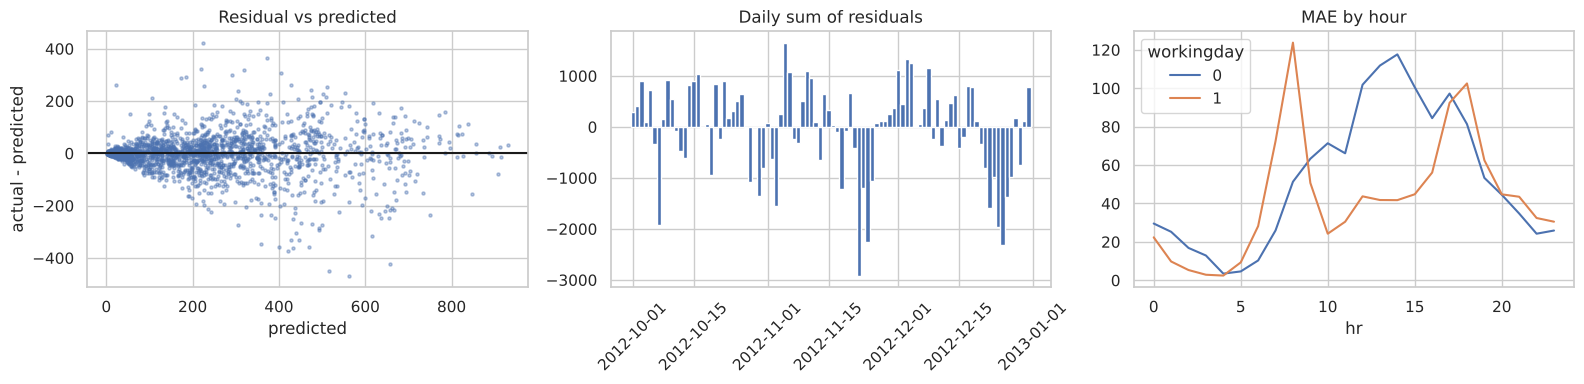

Spearman(|error|, predicted) = 0.6


,sum of residuals
dteday,
2012-11-22,"-2,914.400"
2012-12-25,"-2,313.933"
2012-11-24,"-2,250.580"
2012-12-24,"-1,959.660"
2012-10-07,"-1,928.660"


,hours,MAE,mean error
"working-day peaks 7-8, 17-18",242.000,97.772,25.239
other hours,"1,926.000",39.357,-5.231
rain/snow hours,160.000,61.359,-7.604
holiday hours,95.000,81.016,-52.262
Hurricane Sandy 29-30 Oct,12.000,121.692,-113.311


,ts,workingday,weathersit,cnt,pred,error
16454,2012-11-23 08:00:00,1,1,94,561.487,-467.487
17196,2012-12-24 08:00:00,1,1,66,517.033,-451.033
15661,2012-10-19 18:00:00,1,1,233,657.990,-424.990
16023,2012-11-05 08:00:00,1,2,648,224.710,423.290
17228,2012-12-25 17:00:00,0,2,50,422.003,-372.003
15555,2012-10-15 08:00:00,1,2,737,371.713,365.287
16440,2012-11-22 18:00:00,0,1,70,432.610,-362.610
16439,2012-11-22 17:00:00,0,1,109,468.493,-359.493


In [16]:
# Part 4. Residuals and error groups (random forest, test period)
res = test[['ts', 'dteday', 'hr', 'workingday', 'holiday', 'weathersit', 'cnt']].copy()
res['pred'] = p_rf
res['error'] = res['cnt'] - res['pred']
res['abs_error'] = res['error'].abs()

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].scatter(res['pred'], res['error'], s=5, alpha=0.4); ax[0].axhline(0, color='k')
ax[0].set(title='Residual vs predicted', xlabel='predicted', ylabel='actual - predicted')
day_err = res.groupby('dteday')['error'].sum()
ax[1].bar(day_err.index, day_err.values, width=1); ax[1].set_title('Daily sum of residuals'); ax[1].tick_params(axis='x', rotation=45)
res.groupby(['hr', 'workingday'])['abs_error'].mean().unstack().plot(ax=ax[2], title='MAE by hour')
plt.tight_layout(); plt.savefig(FIG / 'f5_residuals.png', dpi=150); plt.show()

print('Spearman(|error|, predicted) =', round(stats.spearmanr(res['abs_error'], res['pred'])[0], 3))
display(day_err.sort_values().head(5).to_frame('sum of residuals'))

peak = res['hr'].isin([7, 8, 17, 18]) & (res['workingday'] == 1)
rain = res['weathersit'] == 3
sandy = res['dteday'].isin(pd.to_datetime(['2012-10-29', '2012-10-30']))
groups = {'working-day peaks 7-8, 17-18': peak, 'other hours': ~peak, 'rain/snow hours': rain,
          'holiday hours': res['holiday'] == 1, 'Hurricane Sandy 29-30 Oct': sandy}
display(pd.DataFrame({g: {'hours': m.sum(), 'MAE': res.loc[m, 'abs_error'].mean(), 'mean error': res.loc[m, 'error'].mean()}
                      for g, m in groups.items()}).T)
display(res.nlargest(8, 'abs_error')[['ts', 'workingday', 'weathersit', 'cnt', 'pred', 'error']])

In [17]:
# Part 4. Feature importance (random forest, impurity-based)
imp = pd.Series(rf.feature_importances_, index=FEATURES).sort_values(ascending=False)
display(imp.to_frame('importance').head(10))

,importance
log_lag168,0.711
log_lag24,0.144
hr_daytype,0.027
weathersit,0.026
hum,0.023
temp,0.019
hr,0.014
weekday,0.011
windspeed,0.009
mnth,0.007


In [18]:
# Part 5. Clustering days by weather
day = df.groupby('dteday').agg(temp_mean=('temp', 'mean'), temp_max=('temp', 'max'),
                               hum_mean=('hum', 'mean'), wind_mean=('windspeed', 'mean'),
                               rain_hours=('weathersit', lambda s: (s == 3).sum()))
day['log_rain_hours'] = np.log1p(day['rain_hours'])
CF = ['temp_mean', 'temp_max', 'hum_mean', 'wind_mean', 'log_rain_hours']
train_days = day.index < '2012-07-01'
cl_prep = Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())])
C = cl_prep.fit_transform(day.loc[train_days, CF])

rows = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(C)
    ward = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(C)
    rng = np.random.default_rng(RANDOM_STATE)
    boot = []
    for b in range(20):
        idx = rng.choice(len(C), len(C), replace=True)
        boot.append(adjusted_rand_score(km.labels_, KMeans(n_clusters=k, n_init=20, random_state=b).fit(C[idx]).predict(C)))
    rows.append({'k': k, 'silhouette': silhouette_score(C, km.labels_),
                 'calinski_harabasz': calinski_harabasz_score(C, km.labels_),
                 'davies_bouldin': davies_bouldin_score(C, km.labels_),
                 'ward_silhouette': silhouette_score(C, ward),
                 'ARI kmeans vs ward': adjusted_rand_score(km.labels_, ward),
                 'bootstrap ARI mean': np.mean(boot), 'bootstrap ARI min': np.min(boot),
                 'smallest cluster': np.bincount(km.labels_).min()})
display(pd.DataFrame(rows))

,k,silhouette,calinski_harabasz,davies_bouldin,ward_silhouette,ARI kmeans vs ward,bootstrap ARI mean,bootstrap ARI min,smallest cluster
0,2,0.288,238.812,1.415,0.274,0.685,0.895,0.779,263
1,3,0.322,267.275,1.084,0.294,0.629,0.935,0.856,120
2,4,0.301,241.353,1.101,0.251,0.401,0.755,0.498,71
3,5,0.270,224.886,1.152,0.236,0.496,0.605,0.417,76
4,6,0.276,222.468,1.098,0.226,0.682,0.814,0.596,73


10 seeds: mean ARI = 0.996, min = 0.985


,days,temp_C,temp_max_C,hum_%,wind_kmh,rain_hours
cluster,,,,,,
0,120,17.800,20.700,79.400,13.900,7.600
1,195,12.900,16.700,52.200,14.600,0.400
2,232,26.300,30.500,62.500,11.600,0.600


workingday,0,1
cluster,,
0,"2,784.000","2,992.000"
1,"2,849.000","3,394.000"
2,"5,455.000","5,082.000"


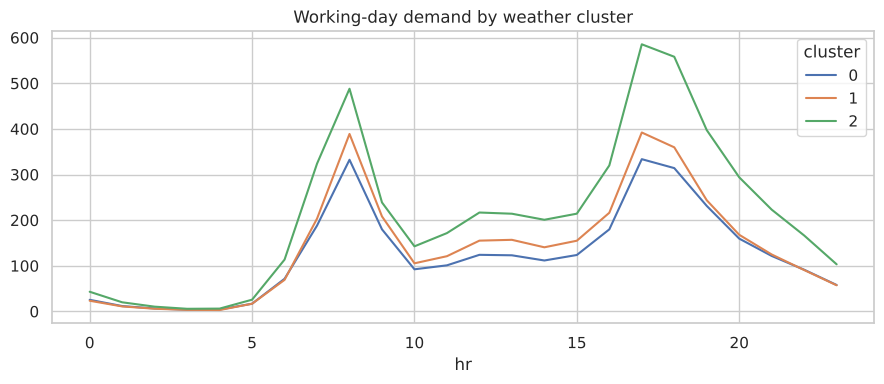

In [19]:
# Part 5. Selected solution k = 3: seeds, profiles, usefulness
K = 3
km = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE).fit(C)
seeds = [adjusted_rand_score(km.labels_, KMeans(n_clusters=K, n_init=1, random_state=s).fit_predict(C)) for s in range(10)]
print(f'10 seeds: mean ARI = {np.mean(seeds):.3f}, min = {np.min(seeds):.3f}')

day['cluster'] = km.predict(cl_prep.transform(day[CF]))
d_tr = day[train_days]
profile = pd.DataFrame({'days': d_tr.groupby('cluster').size(),
                        'temp_C': d_tr.groupby('cluster')['temp_mean'].mean() * 41,
                        'temp_max_C': d_tr.groupby('cluster')['temp_max'].mean() * 41,
                        'hum_%': d_tr.groupby('cluster')['hum_mean'].mean() * 100,
                        'wind_kmh': d_tr.groupby('cluster')['wind_mean'].mean() * 67,
                        'rain_hours': d_tr.groupby('cluster')['rain_hours'].mean()})
display(profile.round(1))

# outcome used only after clustering
dd = daily.join(day['cluster'])
display(dd[dd.index < '2012-07-01'].groupby(['cluster', 'workingday'])['cnt'].mean().unstack().round(0))
h = df[df['dteday'] < '2012-07-01'].merge(day[['cluster']], left_on='dteday', right_index=True)
h[h['workingday'] == 1].groupby(['hr', 'cluster'])['cnt'].mean().unstack().plot(figsize=(9, 4), title='Working-day demand by weather cluster')
plt.tight_layout(); plt.savefig(FIG / 'f6_clusters.png', dpi=150); plt.show()

days: 731 | missing days: 0 | days with < 20 recorded hours: 8


,model,partition,n,MAE,RMSE,R2
0,Seasonal naive (same weekday last week),"test Oct-Dec 2012, 92 days",92,"1,457.587","2,047.168",-0.137
1,Ridge: trend + month + weekday + weather,"test Oct-Dec 2012, 92 days",92,976.756,"1,486.004",0.401


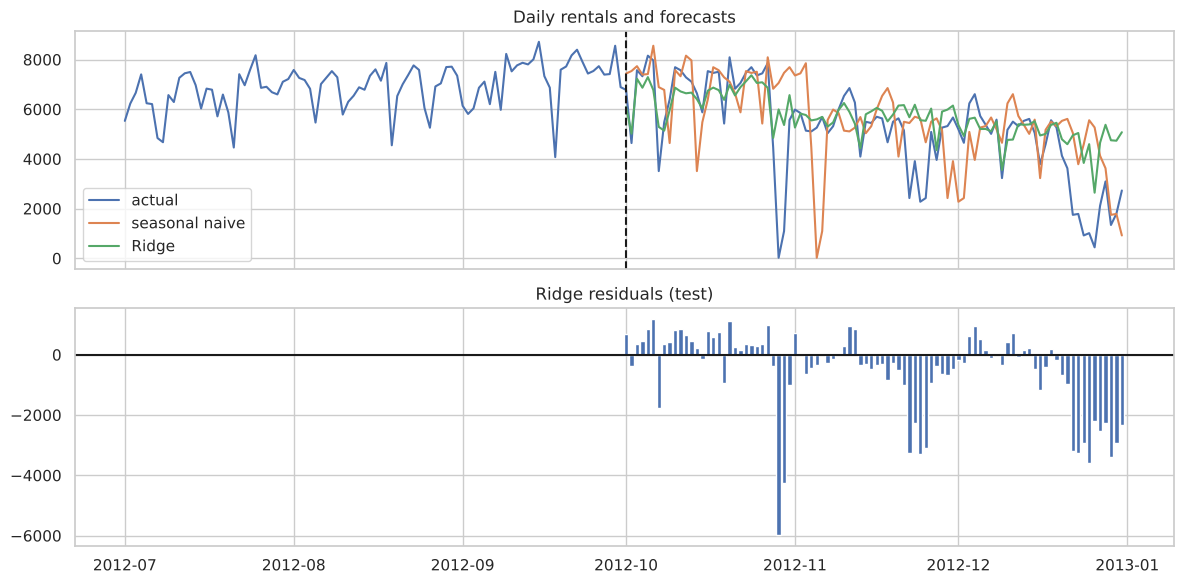

mean residual: -538


,residual
dteday,
2012-10-29,"-5,970.623"
2012-10-30,"-4,269.338"
2012-12-25,"-3,582.358"
2012-12-29,"-3,409.305"
2012-11-24,"-3,281.831"


dteday
2011-01   1,232.000
2011-02   1,722.000
2011-03   2,066.000
2011-04   3,162.000
2011-05   4,381.000
2011-06   4,784.000
2011-07   4,559.000
2011-08   4,409.000
2011-09   4,247.000
2011-10   3,984.000
2011-11   3,406.000
2011-12   2,817.000
2012-01   3,121.000
2012-02   3,556.000
2012-03   5,319.000
2012-04   5,807.000
2012-05   6,318.000
2012-06   6,761.000
2012-07   6,568.000
2012-08   6,919.000
2012-09   7,286.000
2012-10   6,414.000
2012-11   5,089.000
2012-12   3,991.000
Freq: M


In [20]:
# Part 6. Daily time series: seasonal naive vs Ridge
ts = daily['cnt'].asfreq('D')
print('days:', len(ts), '| missing days:', ts.isna().sum(), '| days with < 20 recorded hours:', (daily['hours'] < 20).sum())
d = daily.copy()
d['t'] = np.arange(len(d))                                # trend
d_train, d_test = d[d.index < '2012-10-01'], d[d.index >= '2012-10-01']

naive = ts.shift(7)[d_test.index]                         # same weekday last week

D_NUM = ['t', 'temp', 'hum', 'windspeed', 'rain_hours', 'workingday', 'holiday']
D_CAT = ['mnth', 'weekday']
d_prep = ColumnTransformer([('c', OneHotEncoder(handle_unknown='ignore'), D_CAT),
                            ('n', Pipeline([('i', SimpleImputer(strategy='median')), ('s', StandardScaler())]), D_NUM)])
d_model = Pipeline([('p', d_prep), ('m', Ridge(alpha=1.0))]).fit(d_train[D_NUM + D_CAT], d_train['cnt'])
d_pred = pd.Series(d_model.predict(d_test[D_NUM + D_CAT]), index=d_test.index)

display(pd.DataFrame([reg_metrics('Seasonal naive (same weekday last week)', 'test Oct-Dec 2012, 92 days', d_test['cnt'], naive),
                      reg_metrics('Ridge: trend + month + weekday + weather', 'test Oct-Dec 2012, 92 days', d_test['cnt'], d_pred)]))

d_res = d_test['cnt'] - d_pred
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(ts['2012-07-01':], label='actual'); ax[0].plot(naive, label='seasonal naive'); ax[0].plot(d_pred, label='Ridge')
ax[0].axvline(pd.Timestamp('2012-10-01'), color='k', ls='--'); ax[0].legend(); ax[0].set_title('Daily rentals and forecasts')
ax[1].bar(d_res.index, d_res.values); ax[1].axhline(0, color='k'); ax[1].set_title('Ridge residuals (test)')
plt.tight_layout(); plt.savefig(FIG / 'f7_timeseries.png', dpi=150); plt.show()
print('mean residual:', round(d_res.mean()))
display(d_res.sort_values().head(5).to_frame('residual'))
print(ts.groupby(ts.index.to_period('M')).mean().round(0).to_string())

In [21]:
# Part 7. Text check and MLP compared with the best model (same split)
print('Text columns:', [c for c in raw.columns if raw[c].dtype == object or str(raw[c].dtype) in ('str', 'string')])

rows = []
for h in [(32,), (64, 32)]:
    mlp = Pipeline([('prep', make_prep()),
                    ('m', MLPRegressor(hidden_layer_sizes=h, alpha=1e-3, max_iter=300, early_stopping=True,
                                       random_state=RANDOM_STATE))]).fit(train[FEATURES], np.log1p(y_tr))
    rows.append(reg_metrics(f'MLP {h}', 'validation', y_val, np.expm1(mlp.predict(val[FEATURES]))))
display(pd.DataFrame(rows))

best_h = [(32,), (64, 32)][int(np.argmin([r['RMSE'] for r in rows]))]
mlp = Pipeline([('prep', make_prep()),
                ('m', MLPRegressor(hidden_layer_sizes=best_h, alpha=1e-3, max_iter=300, early_stopping=True,
                                   random_state=RANDOM_STATE))]).fit(dev[FEATURES], np.log1p(y_dev))
display(pd.DataFrame([reg_metrics(f'MLP {best_h}', 'test Oct-Dec 2012', y_test, np.expm1(mlp.predict(test[FEATURES]))),
                      final.iloc[2].to_dict()]))

Text columns: []


,model,partition,n,MAE,RMSE,R2
0,"MLP (32,)",validation,2208,40.334,62.991,0.926
1,"MLP (64, 32)",validation,2208,45.299,71.577,0.904


,model,partition,n,MAE,RMSE,R2
0,"MLP (32,)",test Oct-Dec 2012,2168,45.778,71.716,0.873
1,Random forest,test Oct-Dec 2012,2168,45.877,74.285,0.864
